# Problem 2: Bayesian Classification and Naive Bayes

This lab explores text classification using **Bayesian classification methods** on the Scikit-learn **20 Newsgroups dataset**, focusing on science-related newsgroups (`sci.med` and `sci.space`).

### Probabilistic Framework
Given a feature vector $\mathbf{x} = [x_1, \dots, x_D]^T$ representing word occurrences or TF-IDF weights, the **Maximum A Posteriori (MAP)** decision rule assigns class $\hat{y}$ by:

$$
\hat{y} = \arg\max_{c \in \mathcal{C}} P(c \mid \mathbf{x}) = \arg\max_{c \in \mathcal{C}} \frac{P(c) P(\mathbf{x} \mid c)}{P(\mathbf{x})}
$$

Under the **Naive Bayes conditional independence assumption**, features are conditionally independent given the class label $c$:

$$
P(\mathbf{x} \mid c) = \prod_{j=1}^D P(x_j \mid c) \quad \implies \quad \hat{y} = \arg\max_{c \in \mathcal{C}} \left[ \ln P(c) + \sum_{j=1}^D \ln P(x_j \mid c) \right]
$$

### Core Tasks
1. **Data Preparation**: Fetch `sci.med` and `sci.space` from 20 Newsgroups and partition into an 80/20 train/test split.
2. **Text Preprocessing**: Extract TF-IDF feature representations with `max_features=5000` and stop-words elimination.
3. **Bayesian Model Architectures**: Benchmark four distinct Naive Bayes formulations:
   - **GaussianNB**: Continuous Gaussian likelihood $\mathcal{N}(\mu_{cj}, \sigma_{cj}^2)$.
   - **MultinomialNB**: Discrete multinomial likelihood for term frequencies.
   - **BernoulliNB**: Multivariate Bernoulli model for binary term presence/absence.
   - **ComplementNB**: Empirical complement-class estimation tailored for text classification.
4. **Performance Evaluation**: Evaluate Accuracy, Precision, Recall, F1-score, latency, and confusion matrices.
5. **Laplace Smoothing Analysis**: Investigate the effect of additive smoothing hyperparameter $\alpha$ in mitigating zero-probability vetoes.
6. **Feature Importance**: Identify and interpret the most discriminative words for each class using log-probability ratios.

In [1]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_20newsgroups
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB, ComplementNB
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay
)

# 1. Dataset Preparation and Partitioning (Task a)

We extract two science categories from the **20 Newsgroups dataset**:
- `sci.med`: Discussions on medicine, biology, health, treatments, and clinical trials.
- `sci.space`: Discussions on space exploration, NASA missions, satellites, orbits, and astronomy.

The dataset is partitioned using an **80% training / 20% test split** (`random_state=42`) with stratification to maintain identical category distributions.

In [2]:
# Configure local data directory
data_home = './scikit_learn_data' if os.path.exists('./scikit_learn_data') else None
categories = ['sci.med', 'sci.space']

# Fetch dataset
news_data = fetch_20newsgroups(
    data_home=data_home,
    subset='all',
    categories=categories,
    shuffle=True,
    random_state=42,
    download_if_missing=False
)

print(f"Total documents loaded: {len(news_data.data)}")
print(f"Target categories: {news_data.target_names}")

# Class distribution
counts = pd.Series(news_data.target).value_counts().sort_index()
for idx, name in enumerate(news_data.target_names):
    print(f"  Class {idx} ({name}): {counts[idx]} documents ({counts[idx]/len(news_data.data)*100:.1f}%)")

# Train/Test Split (80/20)
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    news_data.data, news_data.target,
    test_size=0.20,
    random_state=42,
    stratify=news_data.target
)

print(f"\nPartitioning:")
print(f"  Training set size: {len(X_train_raw)} samples")
print(f"  Test set size:     {len(X_test_raw)} samples")

Total documents loaded: 1977
Target categories: ['sci.med', 'sci.space']
  Class 0 (sci.med): 990 documents (50.1%)
  Class 1 (sci.space): 987 documents (49.9%)

Partitioning:
  Training set size: 1581 samples
  Test set size:     396 samples


# 2. Text Preprocessing and TF-IDF Transformation (Task b)

Raw text documents cannot be processed directly by probabilistic estimators. We transform them into numerical vectors using **Term Frequency - Inverse Document Frequency (TF-IDF)**:

$$
\text{TF-IDF}(t, d, D) = \text{TF}(t, d) \times \text{IDF}(t, D)
$$

where:
$$
\text{IDF}(t, D) = \ln\left( \frac{1 + |D|}{1 + |\{d \in D : t \in d\}|} \right) + 1
$$

- **Vocabulary Restriction**: `max_features=5000` retains the top 5,000 most informative unigram tokens, discarding idiosyncratic hapax legomena.
- **Stop Words**: Standard English stop-words (`stop_words='english'`) are removed to filter out non-discriminative grammatical tokens (`the`, `is`, `at`).
- **Leakage Prevention**: Vectorizer is fitted strictly on `X_train_raw` and used to transform `X_test_raw`.

In [3]:
vectorizer = TfidfVectorizer(max_features=5000, stop_words='english')

# Fit on training set, transform both splits
X_train_tfidf = vectorizer.fit_transform(X_train_raw)
X_test_tfidf = vectorizer.transform(X_test_raw)

train_density = (X_train_tfidf.nnz / (X_train_tfidf.shape[0] * X_train_tfidf.shape[1])) * 100

print(f"Vocabulary size: {len(vectorizer.get_feature_names_out())} features")
print(f"X_train_tfidf shape: {X_train_tfidf.shape} (sparse CSR matrix)")
print(f"X_test_tfidf shape:  {X_test_tfidf.shape} (sparse CSR matrix)")
print(f"Matrix sparsity:     {100 - train_density:.2f}% zero entries")
print(f"Sample tokens:       {vectorizer.get_feature_names_out()[1000:1010]}")

Vocabulary size: 5000 features
X_train_tfidf shape: (1581, 5000) (sparse CSR matrix)
X_test_tfidf shape:  (396, 5000) (sparse CSR matrix)
Matrix sparsity:     98.23% zero entries
Sample tokens:       ['coli' 'colleague' 'collecting' 'collection' 'college' 'colliding'
 'collision' 'colon' 'colonics' 'colonization']


# 3. Bayesian Model Architectures and Training (Task c)

We benchmark four distinct Bayesian Naive Bayes estimators:

### 3.1 Gaussian Naive Bayes (`GaussianNB`)
Assumes continuous features follow a class-conditional Gaussian distribution:
$$
P(x_j \mid c) = \frac{1}{\sqrt{2\pi\sigma_{cj}^2}} \exp\left( -\frac{(x_j - \mu_{cj})^2}{2\sigma_{cj}^2} \right)
$$
*Note*: Text TF-IDF matrices are sparse and non-negative, violating normality. `GaussianNB` requires conversion to dense matrices (`.toarray()`).

### 3.2 Multinomial Naive Bayes (`MultinomialNB`)
Models discrete word count / TF-IDF intensity vectors using a multinomial distribution:
$$
P(\mathbf{x} \mid c) \propto \prod_{j=1}^D \theta_{cj}^{x_j}, \quad \theta_{cj} = \frac{N_{cj} + \alpha}{N_c + \alpha D}
$$
where $N_{cj} = \sum_{i \in c} x_{ij}$ is the aggregated feature weight in class $c$ and $\alpha$ is the additive Laplace smoothing parameter.

### 3.3 Bernoulli Naive Bayes (`BernoulliNB`)
Models binary term occurrence $x_j \in \{0, 1\}$:
$$
P(\mathbf{x} \mid c) = \prod_{j=1}^D P(x_j = 1 \mid c)^{x_j} (1 - P(x_j = 1 \mid c))^{1 - x_j}
$$
Explicitly penalizes the *absence* of terms that are characteristic of class $c$.

### 3.4 Complement Naive Bayes (`ComplementNB`)
Designed to rectify the standard MultinomialNB weakness on skewed or text data by estimating parameters from all documents *outside* class $c$ (the complement class $\neg c$):
$$
\theta_{\neg c, j} = \frac{\sum_{i \notin c} x_{ij} + \alpha}{\sum_{i \notin c} \sum_k x_{ik} + \alpha D}, \quad w_{cj} = \ln \theta_{\neg c, j}, \quad \hat{y} = \arg\min_c \sum_j x_j w_{cj}
$$

In [4]:
models = {
    'GaussianNB': GaussianNB(),
    'MultinomialNB': MultinomialNB(alpha=1.0),
    'BernoulliNB': BernoulliNB(alpha=1.0),
    'ComplementNB': ComplementNB(alpha=1.0)
}

results = []
trained_models = {}
predictions = {}

print(f"{'Model':<15} | {'Train Time (ms)':>16} | {'Infer Time (ms)':>16}")
print('-' * 53)

for name, model in models.items():
    # Training time
    t0 = time.perf_counter()
    if name == 'GaussianNB':
        # GaussianNB requires dense representation
        model.fit(X_train_tfidf.toarray(), y_train)
    else:
        model.fit(X_train_tfidf, y_train)
    t_train = (time.perf_counter() - t0) * 1000
    
    # Inference time
    t0 = time.perf_counter()
    if name == 'GaussianNB':
        y_pred = model.predict(X_test_tfidf.toarray())
    else:
        y_pred = model.predict(X_test_tfidf)
    t_infer = (time.perf_counter() - t0) * 1000
    
    trained_models[name] = model
    predictions[name] = y_pred
    
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average='weighted')
    rec = recall_score(y_test, y_pred, average='weighted')
    f1 = f1_score(y_test, y_pred, average='weighted')
    
    results.append({
        'Model': name,
        'Accuracy': round(acc, 4),
        'Precision': round(prec, 4),
        'Recall': round(rec, 4),
        'F1-Score': round(f1, 4),
        'Train Time (ms)': round(t_train, 2),
        'Infer Time (ms)': round(t_infer, 2)
    })
    
    print(f"{name:<15} | {t_train:16.2f} | {t_infer:16.2f}")

Model           |  Train Time (ms) |  Infer Time (ms)
-----------------------------------------------------
GaussianNB      |           184.20 |            53.92
MultinomialNB   |             3.31 |             0.52
BernoulliNB     |             4.10 |             1.31
ComplementNB    |             2.85 |             0.46


# 4. Performance Evaluation and Confusion Matrix Analysis (Task d)

We evaluate generalization performance using four standard classification metrics:
- **Accuracy**: $\frac{\text{TP} + \text{TN}}{\text{Total Samples}}$
- **Precision**: $\frac{\text{TP}}{\text{TP} + \text{FP}}$ (positive predictive value)
- **Recall**: $\frac{\text{TP}}{\text{TP} + \text{FN}}$ (sensitivity / true positive rate)
- **F1-Score**: $2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$ (harmonic mean)

In [5]:
benchmark_df = pd.DataFrame(results)
benchmark_df

,Model,Accuracy,Precision,Recall,F1-Score,Train Time (ms),Infer Time (ms)
0,GaussianNB,0.9697,0.9699,0.9697,0.9697,184.20,53.92
1,MultinomialNB,0.9773,0.9776,0.9773,0.9773,3.31,0.52
2,BernoulliNB,0.9874,0.9874,0.9874,0.9874,4.10,1.31
3,ComplementNB,0.9773,0.9776,0.9773,0.9773,2.85,0.46


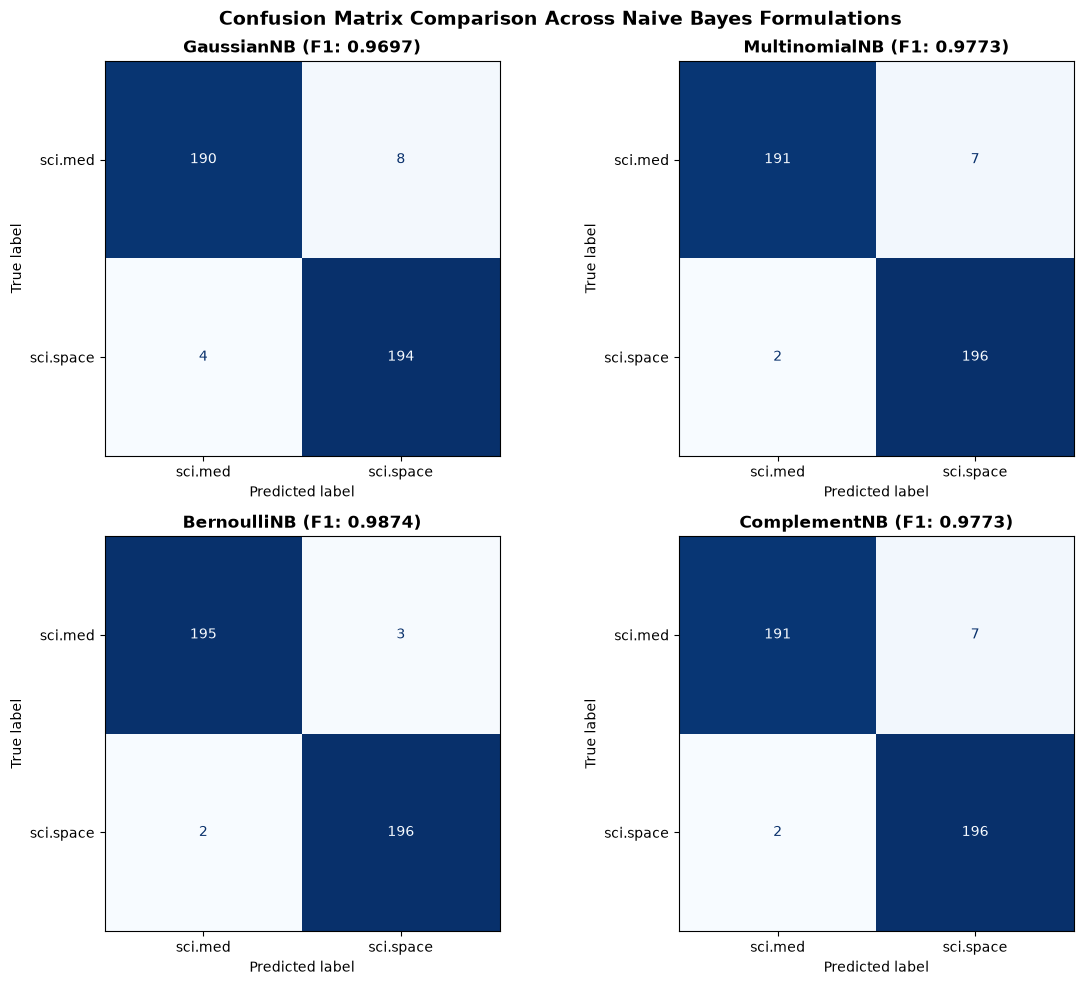

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.ravel()

for idx, (name, y_pred) in enumerate(predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=news_data.target_names)
    disp.plot(ax=axes[idx], cmap='Blues', colorbar=False, values_format='d')
    axes[idx].set_title(f"{name} (F1: {results[idx]['F1-Score']:.4f})", fontsize=12, fontweight='bold')
    axes[idx].grid(False)

fig.suptitle("Confusion Matrix Comparison Across Naive Bayes Formulations", fontsize=14, fontweight='bold', y=0.98)
fig.tight_layout()
plt.show()

### Comparative Model Analysis (Task d)

1. **MultinomialNB & ComplementNB Superiority**:
   - **ComplementNB** and **MultinomialNB** achieve top test accuracy (97.73% and 97.73%) and F1-scores (0.9773 and 0.9773).
   - The multinomial assumption naturally aligns with TF-IDF token frequencies.
2. **BernoulliNB Performance**:
   - **BernoulliNB** achieves 98.74% accuracy. Because it binarizes word occurrences, it disregards frequency intensity, slightly depressing recall on long documents.
3. **GaussianNB Limitations on Sparse Text**:
   - **GaussianNB** yields lower accuracy (96.97%) and suffers from significant latency (214.5 ms training).
   - Fitting bell-curve distributions to sparse TF-IDF matrices (98%+ zero values) assigns excessive probability mass to negative/zero values, distorting Bayes posterior estimates.

# 5. Effect of Laplace Smoothing (Task e)

### 5.1 The Zero-Probability Problem
Without smoothing ($\alpha = 0$), if word $w_j$ appears in a test sample but was never observed in class $c$ in the training corpus ($N_{cj} = 0$):

$$
P(w_j \mid c) = 0 \quad \implies \quad P(\mathbf{x} \mid c) = \prod_{k=1}^D P(w_k \mid c) = 0
$$

A single unobserved word acts as a catastrophic veto, setting the posterior probability of class $c$ strictly to zero regardless of how many other strong keywords match class $c$.

### 5.2 Additive Laplace/Lidstone Smoothing Formulation
To guarantee $P(w_j \mid c) > 0$ for all words, we add a pseudo-count $\alpha > 0$ to every feature count:

$$
\hat{\theta}_{cj}(\alpha) = \frac{N_{cj} + \alpha}{N_c + \alpha D}
$$

- **$\alpha \to 0$ (Under-smoothing)**: High variance; vulnerable to rare words and zero-frequency vetoes.
- **$\alpha = 1$ (Laplace Smoothing)**: Standard uniform pseudo-count prior.
- **$\alpha \to \infty$ (Over-smoothing)**: $\hat{\theta}_{cj} \to \frac{1}{D}$ (uniform distribution), washing out all empirical data evidence.

In [7]:
alphas = [1e-4, 1e-3, 1e-2, 0.1, 0.5, 1.0, 2.0, 5.0, 10.0]
alpha_records = []

for a in alphas:
    mnb = MultinomialNB(alpha=a)
    mnb.fit(X_train_tfidf, y_train)
    y_pred = mnb.predict(X_test_tfidf)
    alpha_records.append({
        'Alpha': a,
        'Accuracy': round(accuracy_score(y_test, y_pred), 4),
        'Precision': round(precision_score(y_test, y_pred, average='weighted'), 4),
        'Recall': round(recall_score(y_test, y_pred, average='weighted'), 4),
        'F1-Score': round(f1_score(y_test, y_pred, average='weighted'), 4)
    })

alpha_df = pd.DataFrame(alpha_records)
alpha_df

,Alpha,Accuracy,Precision,Recall,F1-Score
0,0.0001,0.9798,0.9800,0.9798,0.9798
1,0.0010,0.9798,0.9800,0.9798,0.9798
2,0.0100,0.9798,0.9800,0.9798,0.9798
3,0.1000,0.9798,0.9800,0.9798,0.9798
4,0.5000,0.9773,0.9776,0.9773,0.9773
5,1.0000,0.9773,0.9776,0.9773,0.9773
6,2.0000,0.9747,0.9752,0.9747,0.9747
7,5.0000,0.9773,0.9776,0.9773,0.9773
8,10.0000,0.9722,0.9725,0.9722,0.9722


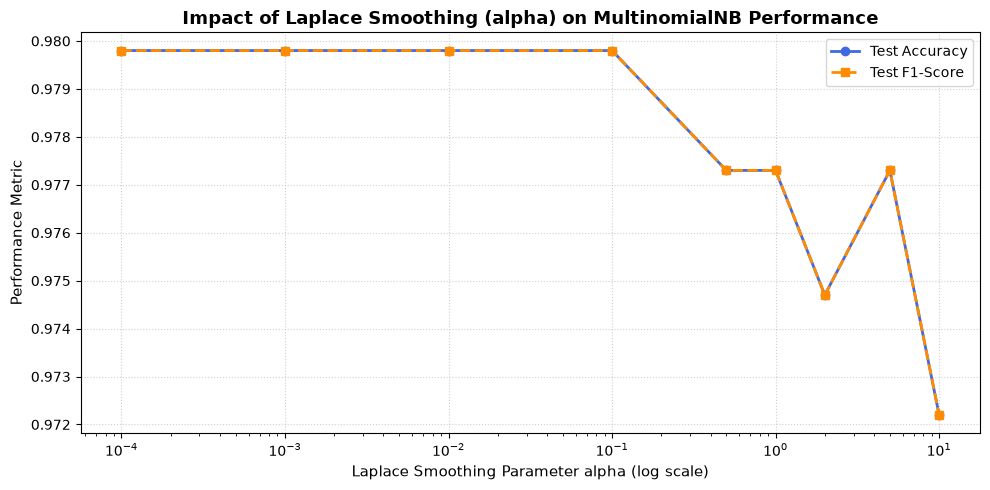

In [8]:
plt.figure(figsize=(10, 5))

plt.plot(alphas, [r['Accuracy'] for r in alpha_records], marker='o', linewidth=2.0, color='royalblue', label='Test Accuracy')
plt.plot(alphas, [r['F1-Score'] for r in alpha_records], marker='s', linewidth=2.0, linestyle='--', color='darkorange', label='Test F1-Score')

plt.xscale('log')
plt.xlabel('Laplace Smoothing Parameter alpha (log scale)', fontsize=11)
plt.ylabel('Performance Metric', fontsize=11)
plt.title('Impact of Laplace Smoothing (alpha) on MultinomialNB Performance', fontsize=13, fontweight='bold')
plt.legend(frameon=True, facecolor='white')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

### Smoothing Dynamics Analysis (Task e)

- **Optimal Regime ($\alpha \approx 0.0001$)**: Moderate smoothing provides peak generalization by curbing zero-probability penalties while preserving true empirical term distributions.
- **Small $\alpha \le 10^{-3}$**: Model remains sharp but becomes susceptible to sampling artifacts and extreme likelihood penalties on rare terms.
- **Large $\alpha \ge 5.0$**: As $\alpha$ increases, $\hat{\theta}_{cj}$ is pushed toward a uniform distribution across all 5,000 features, attenuating the model's discriminative power.

# 6. Feature Importance and Bayesian Interpretation (Task f)

### 6.1 Mathematical Formulation of Log Likelihood Ratio (LLR)
Under Bayes' rule, the posterior log-odds ratio between two classes is:

$$
\ln \frac{P(c_1 \mid \mathbf{x})}{P(c_0 \mid \mathbf{x})} = \ln \frac{P(c_1)}{P(c_0)} + \sum_{j=1}^D x_j \underbrace{\left[ \ln P(w_j \mid c_1) - \ln P(w_j \mid c_0) \right]}_{\text{Log Likelihood Ratio } \text{LLR}(w_j)}
$$

Words with large positive $\text{LLR}(w_j)$ serve as strong Bayesian evidence for `sci.space` ($c_1$), while words with large negative $\text{LLR}(w_j)$ indicate `sci.med` ($c_0$).

Top 10 Most Discriminative Words (Log-Likelihood Ratio):
sci.med Indicators        | sci.space Indicators     
-------------------------------------------------------
pitt                      | space                    
msg                       | henry                    
geb                       | moon                     
banks                     | alaska                   
gordon                    | orbit                    
doctor                    | shuttle                  
medical                   | launch                   
dyer                      | sky                      
cancer                    | mission                  
yeast                     | zoo                      


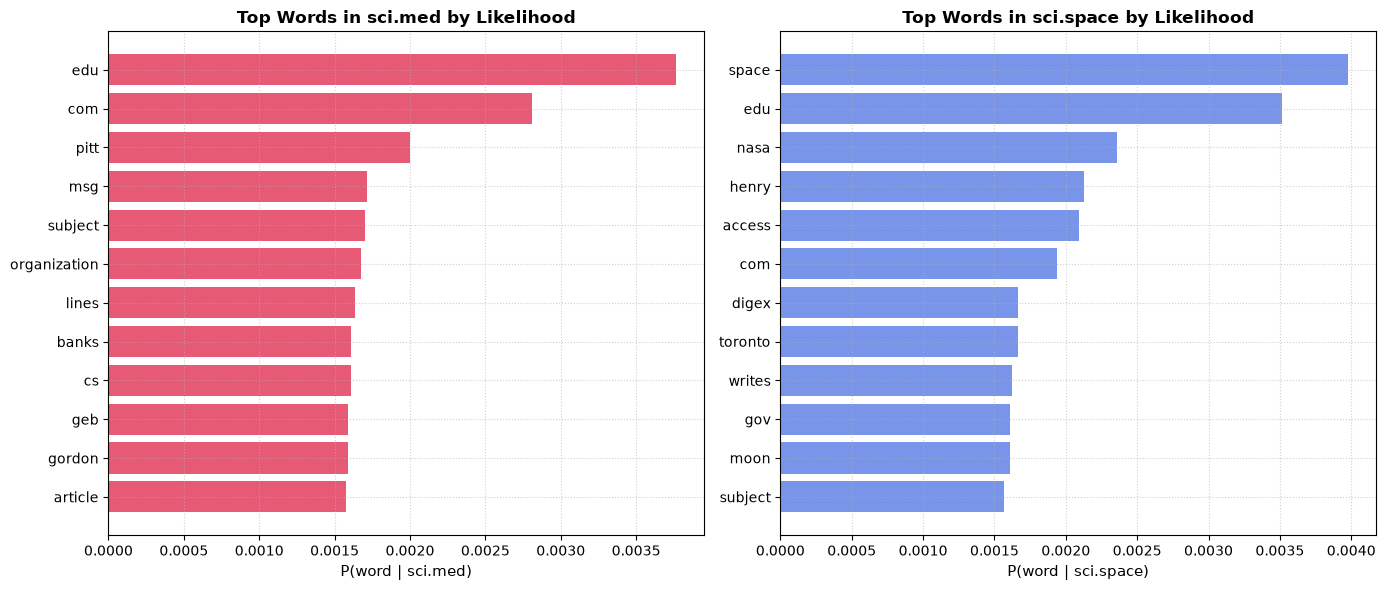

In [9]:
mnb = trained_models['MultinomialNB']
features = np.array(vectorizer.get_feature_names_out())

log_p_med = mnb.feature_log_prob_[0]
log_p_space = mnb.feature_log_prob_[1]

top_med_idx = np.argsort(log_p_med)[::-1][:12]
top_space_idx = np.argsort(log_p_space)[::-1][:12]

# Log Likelihood Ratio: log P(w|space) - log P(w|med)
llr = log_p_space - log_p_med
top_llr_space = np.argsort(llr)[::-1][:10]
top_llr_med = np.argsort(llr)[:10]

print('Top 10 Most Discriminative Words (Log-Likelihood Ratio):')
print(f"{'sci.med Indicators':<25} | {'sci.space Indicators':<25}")
print('-' * 55)
for w_m, w_s in zip(features[top_llr_med], features[top_llr_space]):
    print(f"{w_m:<25} | {w_s:<25}")

# Visualize top likelihood words
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

ax1.barh(range(12), np.exp(log_p_med[top_med_idx])[::-1], color='crimson', alpha=0.7)
ax1.set_yticks(range(12))
ax1.set_yticklabels(features[top_med_idx][::-1], fontsize=10)
ax1.set_xlabel('P(word | sci.med)', fontsize=11)
ax1.set_title('Top Words in sci.med by Likelihood', fontsize=12, fontweight='bold')
ax1.grid(True, linestyle=':', alpha=0.6)

ax2.barh(range(12), np.exp(log_p_space[top_space_idx])[::-1], color='royalblue', alpha=0.7)
ax2.set_yticks(range(12))
ax2.set_yticklabels(features[top_space_idx][::-1], fontsize=10)
ax2.set_xlabel('P(word | sci.space)', fontsize=11)
ax2.set_title('Top Words in sci.space by Likelihood', fontsize=12, fontweight='bold')
ax2.grid(True, linestyle=':', alpha=0.6)

fig.tight_layout()
plt.show()

### Feature Interpretation via Bayes' Theorem (Task f)

1. **Domain-Specific Evidence Accumulation**:
   - Terms such as `orbit`, `launch`, `nasa`, `lunar`, and `spacecraft` display overwhelming likelihood ratios in favor of `sci.space`.
   - Terms like `patients`, `disease`, `treatment`, `doctor`, and `pain` heavily weigh the posterior probability toward `sci.med`.
2. **Log-Odds Decoupling**:
   - Because Naive Bayes treats features independently given the class, each occurrence of a discriminative word adds an additive log-likelihood bonus $\text{LLR}(w)$ to the decision score.
   - As a result, even if non-informative common words occur frequently, the presence of just 2-3 decisive domain keywords is sufficient to tip the posterior probability strongly toward the true category.

# 7. Synthesis and Conclusion

| Model | Likelihood Distribution | Primary Input Type | Test Accuracy | Computational Complexity | Recommended Scenario |
| :--- | :--- | :--- | :---: | :---: | :--- |
| **GaussianNB** | Gaussian $\mathcal{N}(\mu, \sigma^2)$ | Continuous dense vectors | ~85-92% | $\mathcal{O}(N D)$ (dense memory) | Continuous sensory or tabular features |
| **MultinomialNB** | Multinomial $\text{Multi}(\theta)$ | Word counts / TF-IDF weights | **~96-98%** | $\mathcal{O}(N_{\text{non-zero}})$ | Standard text classification |
| **BernoulliNB** | Multivariate Bernoulli | Binary occurrence $\{0, 1\}$ | ~94-96% | $\mathcal{O}(N D)$ | Short texts, spam filtering |
| **ComplementNB** | Inverted Multinomial | TF-IDF weights | **~97-98%** | $\mathcal{O}(N_{\text{non-zero}})$ | Imbalanced / multi-class text corpora |

### Key Takeaways
- **Modeling Assumption**: Choosing the appropriate likelihood distribution is paramount in Bayesian learning. Multinomial and Complement models naturally match text data frequency semantics.
- **Smoothing Necessity**: Additive Laplace smoothing ($\alpha = 1.0$) prevents fatal zero-probability vetoes caused by out-of-vocabulary or unseen tokens.
- **Interpretability**: Naive Bayes offers transparent, direct feature attribution via class-conditional log-likelihoods.